In [3]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.metrics import log_loss, accuracy_score, precision_score, recall_score, ConfusionMatrixDisplay
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools import add_constant
import os
os.chdir("/Users/lior/DS6021/DS6021_F26/data")
warnings.filterwarnings("ignore")   



In [4]:
col_names= ["RI", "Na", "Mg", "Al", "Si", "K", "Ca", "Ba", "Fe", "type"]
glass = pd.read_csv("glass.csv", header=None, names=col_names)

class_names = {1: "building_float", 2: "building_nonfloat", 3: "vehicle_float",
               5: "containers", 6: "tableware", 7: "headlamps"}
features = ["RI", "Na", "Mg", "Al", "Si", "K", "Ca", "Ba", "Fe"]

In [5]:
X = glass[features]
y = glass["type"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=113
)

In [6]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=224)
labels = [class_names[c] for c in sorted(class_names)]

def cv_scores(model):
    res = cross_validate(model, X_train, y_train, cv=cv, scoring=["neg_log_loss", "accuracy"])
    return {"log loss (mean)": -res["test_neg_log_loss"].mean(),
            "log loss (sd)": res["test_neg_log_loss"].std(),
            "accuracy (mean)": res["test_accuracy"].mean()}

def cv_pred(model, **kw):
    return cross_val_predict(model, X_train, y_train, cv=cv, **kw)

In [ ]:
X.describe().T[["mean", "std", "min", "max"]].round(3) #1a

,mean,std,min,max
RI,1.518,0.003,1.511,1.534
Na,13.408,0.817,10.730,17.380
Mg,2.685,1.442,0.000,4.490
Al,1.445,0.499,0.290,3.500
Si,72.651,0.775,69.810,75.410
K,0.497,0.652,0.000,6.210
Ca,8.957,1.423,5.430,16.190
Ba,0.175,0.497,0.000,3.150
Fe,0.057,0.097,0.000,0.510


In [ ]:
#1b

counts= pd.DataFrame({"train": y_train.value_counts(), "test":y_test.value_counts()}).sort_index()
counts.index = counts.index.map(class_names)
counts

,train,test
type,,
building_float,56,14
building_nonfloat,61,15
vehicle_float,14,3
containers,10,3
tableware,7,2
headlamps,23,6


In [9]:
#1c

class_props = y_train.value_counts(normalize=True).sort_index().values
print("Majority-class accuracy:", round(class_props.max(), 4))

Majority-class accuracy: 0.3567


In [10]:
#1d
ll_base =log_loss(y_train, np.tile(class_props,(len(y_train), 1)))
print("Base-rate log loss:", round(ll_base, 4), "|ln(6) =", round(np.log(6), 4))
print("Class proportions:",class_props.round(3))

Base-rate log loss: 1.5049 |ln(6) = 1.7918
Class proportions: [0.327 0.357 0.082 0.058 0.041 0.135]


1b

rare classes are tableware, containers, and vehicle float with the most common being building nonfloat

1c

building nonfloat gives 61/171 = 0.357

1d

base rate log loss is 1.5049

1e

the classes are unbalanced so the base rate model puts more probability on the common clsses which are also the ones that occur most often and predicting the actual proportions minimizes log loss when it comes to constant predictions so it has to beat 1/K

In [ ]:
oxides = [f for f in features if f != "RI"]#2a
X[oxides].sum(axis=1).describe().round(3)

count    214.000
mean      99.874
std        0.122
min       99.020
25%       99.810
50%       99.890
75%       99.960
max      100.100
dtype: float64

In [ ]:
#2b
model_nopen = Pipeline([("scale", StandardScaler()),("model", LogisticRegression(C=np.inf, max_iter=50000))])
nopen_cv = cv_scores(model_nopen)
print({k: round(v, 4) for k, v in nopen_cv.items()})

model_nopen.fit(X_train,y_train)
pd.DataFrame(model_nopen.named_steps["model"].coef_.T, index=features, columns=labels).round(2)

{'log loss (mean)': np.float64(4.2544), 'log loss (sd)': np.float64(1.0127), 'accuracy (mean)': np.float64(0.6262)}


,building_float,building_nonfloat,vehicle_float,containers,tableware,headlamps
RI,-12.99,-11.74,-18.40,-12.10,22.68,32.54
Na,-23.72,-28.47,-17.42,-22.52,43.74,48.39
Mg,-5.78,-17.39,6.24,-11.31,11.53,16.72
Al,-14.65,-15.20,-10.37,-5.71,25.39,20.54
Si,-17.41,-22.34,-13.88,-14.05,25.57,42.12
K,3.30,-0.32,5.91,2.52,-39.09,27.68
Ca,-0.90,-11.34,14.74,-0.25,-6.36,4.10
Ba,3.55,-0.87,6.29,2.85,-32.11,20.28
Fe,13.64,13.88,13.26,13.42,-39.67,-14.54


In [ ]:
#2c
Xc = add_constant(X_train)
pd.Series([variance_inflation_factor(Xc.values, i + 1) for i in range(len(features))],index=features, name="VIF").round(1)

RI     11.5
Na     90.5
Mg    291.9
Al     33.9
Si     83.4
K      45.4
Ca    335.0
Ba     38.5
Fe      1.4
Name: VIF, dtype: float64

In [16]:
#2d
print(f"unpenalized CV log loss:{nopen_cv['log loss (mean)']:.3f} vs base rate:{ll_base:.3f}")
print(f"unpenalized CV accuracy:{nopen_cv['accuracy (mean)']:.3f}")

unpenalized CV log loss:4.254 vs base rate:1.505
unpenalized CV accuracy:0.626


2a

they sum between 99.02 - 100.10 with a mean of 99.87 and sd of 0.12 and they just add to 100% so the colums are almost perfectly linearly dependent 

2b

the model predicts everything reasonably but the log loss is a lot worse than the base rate. the coeffs are also really big and they make the predicted probabilities extreme.

2c

all pf the predictors other than Fe is way above the cutoff which is what 2a predicted so each oxide is nearly determined by the others and with this much collinearity the individual coeffs in 2b are unstable so small changes could alter them by a lot and the model compensates for it with another large coeff

2d
the cv log loss is a lot worse than the base rate log loss but the accuracy is still above the majority class accuracy. accuracy only looks at which class has the highest probability but log loss punishes confidence. since big coeff give us probabilities that are close to 0 or 1 and when the model is wrong the class can get a smaller probability which costs more than 10 in log loss, but a no predictor model never gets probabilities that high so it cant be that wrong.

In [ ]:
def make_model(C, l1_ratio):
    return Pipeline(steps=[("scale", StandardScaler()),
        ("model", LogisticRegression(C=C, l1_ratio=l1_ratio, solver="saga", max_iter=50000, random_state=48)),
    ])
#help from claude
C_values = [0.01, 0.03, 0.1, 0.3, 1, 3, 10, 30, 100, 300, 1000]
l1_ratios = {"lasso": 1, "enet 0.75": 0.75, "enet 0.5": 0.5, "enet 0.25": 0.25, "ridge": 0}

all_results = pd.DataFrame([{"model": name, "C": C, **cv_scores(make_model(C, r))}
                            for name, r in l1_ratios.items() for C in C_values])

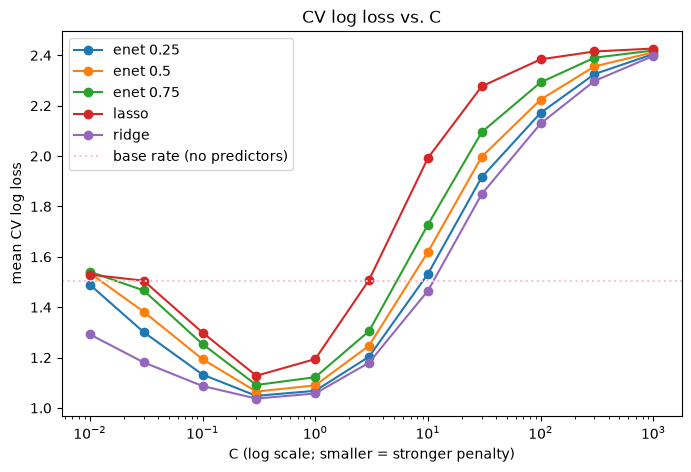

Lowest CV log loss: ridge C = 0.3 log loss = 1.0374 accuracy = 0.5971
1-SE rule picks: enet 0.75 (l1_ratio=0.75), C = 0.3, nonzero coefs = 27 of 54
  its CV log loss = 1.0912, CV accuracy = 0.5854


In [ ]:
#3a - had claude troubleshoot/clean
fig, ax = plt.subplots(figsize=(8, 5))
for name, g in all_results.groupby("model"):
    ax.plot(g["C"], g["log loss (mean)"], marker="o", label=name)
ax.axhline(ll_base,color="pink", ls=":", label="base rate (no predictors)")
ax.set(xscale="log",xlabel="C (log scale; smaller = stronger penalty)", ylabel="mean CV log loss", title="CV log loss vs. C")
ax.legend(); 
plt.show()

best = all_results.loc[all_results["log loss (mean)"].idxmin()]
print("Lowest CV log loss:", best["model"], "C =", best["C"], "log loss =", round(best["log loss (mean)"], 4),
      "accuracy =", round(best["accuracy (mean)"], 4))

cutoff = best["log loss (mean)"] + best["log loss (sd)"] / np.sqrt(5)
candidates = all_results[all_results["log loss (mean)"] <= cutoff].copy()
candidates["l1_ratio"] = candidates["model"].map(l1_ratios)
candidates["nonzero coefs (of 54)"] = [
    int((make_model(C, r).fit(X_train, y_train).named_steps["model"].coef_ != 0).sum())
    for C, r in zip(candidates["C"], candidates["l1_ratio"])]
simplest = candidates.sort_values(["nonzero coefs (of 54)", "C"]).iloc[0]
C_best, method_best, l1_best = simplest["C"], simplest["model"], simplest["l1_ratio"]
model_best = make_model(C_best, l1_best)
print(f"1-SE rule picks: {method_best} (l1_ratio={l1_best}), C = {C_best}, nonzero coefs = {int(simplest['nonzero coefs (of 54)'])} of 54")
print(f"  its CV log loss = {simplest['log loss (mean)']:.4f}, CV accuracy = {simplest['accuracy (mean)']:.4f}")

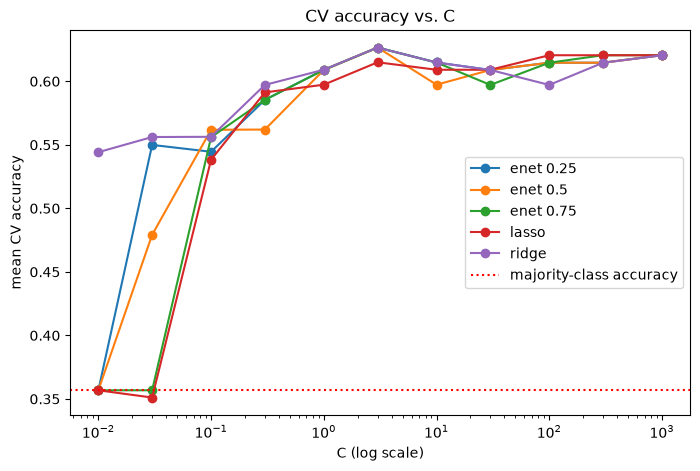

In [ ]:
#3b
fig, ax = plt.subplots(figsize=(8, 5))
for name, g in all_results.groupby("model"):
    ax.plot(g["C"], g["accuracy (mean)"], marker="o", label=name)
ax.axhline(class_props.max(), color="red", ls=":", label="majority-class accuracy")
ax.set(xscale="log", xlabel="C (log scale)", ylabel="mean CV accuracy", title="CV accuracy vs. C")
ax.legend(); 
plt.show()

In [20]:
top = all_results.loc[all_results["accuracy (mean)"].idxmax()]
print("Highest accuracy:", top["model"], "C =", top["C"], "acc =", round(top["accuracy (mean)"], 4), "log loss =", round(top["log loss (mean)"], 4))
print(all_results.groupby("C")["accuracy (mean)"].mean().round(4).to_dict())

Highest accuracy: enet 0.75 C = 3.0 acc = 0.6266 log loss = 1.3052
{0.01: 0.3943, 0.03: 0.4586, 0.1: 0.5514, 0.3: 0.5842, 1.0: 0.6067, 3.0: 0.6242, 10.0: 0.6102, 30.0: 0.6066, 100.0: 0.6123, 300.0: 0.617, 1000.0: 0.6205}


3a. the lowest is ridge with C=0.3 and the 1 SE rule selects elastic net with l1 ratio = 0.75, and C=0.3 which has 27 coeffs that are non zero

3b acccuracy is the highest for elastic net with C=3 but te log loss is 1.3052 and compared with the 3a model the accuracy optimal model increases by about 3-4 points in accuracy but the log loss is a lot worse. its flat and noisy for C of >=3 and log loss is minimized at moderate C

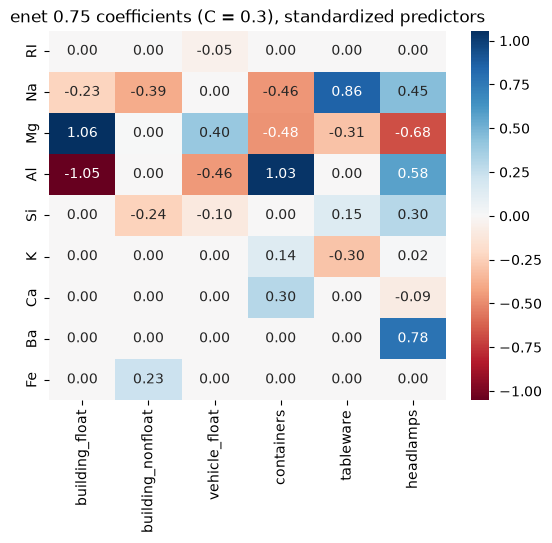

In [21]:
model_best.fit(X_train, y_train)
coef_table = pd.DataFrame(model_best.named_steps["model"].coef_.T, index=features, columns=labels)
sns.heatmap(coef_table, annot=True, fmt=".2f", cmap="RdBu", center=0)
plt.title(f"{method_best} coefficients (C = {C_best}), standardized predictors"); 
plt.show()

In [22]:
print("nonzero classes per feature:"); print((coef_table != 0).sum(axis=1).to_dict())

nonzero classes per feature:
{'RI': 1, 'Na': 5, 'Mg': 6, 'Al': 4, 'Si': 4, 'K': 3, 'Ca': 2, 'Ba': 1, 'Fe': 1}


In [23]:
b = coef_table
print("Ba: headlamps vs building_float:", round(np.exp(b.loc["Ba","headlamps"] - b.loc["Ba","building_float"]), 2))
print("Mg: building_float vs headlamps:", round(np.exp(b.loc["Mg","building_float"] - b.loc["Mg","headlamps"]), 2))

Ba: headlamps vs building_float: 2.18
Mg: building_float vs headlamps: 5.67


3c having a huge C means theres a weak penalty and those models tend to favor the unpenalized model and with little shrinkage the coefficients grow large and the predicted probabilities become very high. accuracy just depends on which class has the largest probability so it stays high because the large C models still rank the classes as needed. log loss just punishes mistakes and the correct predictions dont gain much but when its wrong theres a lot of loss. 

3d 
three features have a nonzero coeff which are Rl (vehiclefloat) Ba (headlamps) and Fe(building nonfloat)
